<a href="https://colab.research.google.com/github/Idan-A/backtest-that-disproves-itself/blob/main/notebook/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A backtest that tries to disprove itself

**Question.** Can a simple machine-learning model choose, each month, 3 out of 6 ETFs (US stocks, international stocks, bonds, corporate bonds, gold, short-term Treasuries) and do better than simple portfolios after trading costs?

**Method.** Every month a Ridge regression is trained only on the past 60 months to predict next month's return of each ETF from three simple signals (3-month momentum, 12-month momentum, recent volatility). We buy the 3 ETFs with the highest predictions, pay costs, and compare with a 60/40 portfolio, an equal-weight portfolio and 200 random portfolios. The goal is not to show a profit but to check carefully whether the result holds up.

**Fixed choices.** All settings are declared in the first code cell and were not changed after looking at results.

## 1. Fixed choices
This cell loads the libraries and writes down every setting of the experiment in one place. Fixing them before seeing any result protects us from tuning the strategy until it looks good.

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

TICKERS = ["SPY", "EFA", "AGG", "LQD", "GLD", "SHY"]  # List of selected assets
START, END = "2004-01-01", "2026-11-01"   # Data download date range
RIDGE_ALPHA = 1.0          # Ridge regression regularization strength
TRAIN_MONTHS = 60          # Historical rolling training window
COST = 0.0010              # Transaction cost per trade
RISK_FREE = 0.0            # Baseline benchmark risk-free rate
N_PLACEBO = 200            # Number of random portfolios
SEED = 42                  # Random number generator seed
TOP_K = 3                  # Target number of assets bought

## 2. Data
We download daily prices adjusted for dividends and splits, and keep only the days where all 6 ETFs exist (GLD starts in November 2004). From these we take the last price of each month and compute monthly returns.

In [ ]:
prices = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)["Close"]
prices = prices[TICKERS].dropna()               # common sample
monthly_px = prices.resample("ME").last()
monthly_ret = monthly_px.pct_change().dropna()

print("Daily prices:", prices.index[0].date(), "to", prices.index[-1].date(), prices.shape)
print("Monthly returns:", monthly_ret.index[0].date(), "to", monthly_ret.index[-1].date(), monthly_ret.shape)
(monthly_ret.mean() * 12).round(3).rename("average annual return").to_frame().T

Daily prices: 2004-11-18 to 2026-10-30 (5522, 6)
Monthly returns: 2004-12-31 to 2026-10-31 (263, 6)


Ticker,SPY,EFA,AGG,LQD,GLD,SHY
average annual return,0.114,0.075,0.03,0.041,0.109,0.02


## 3. Benchmarks and metrics
Before building any model we need something to beat: a 60/40 portfolio (60% SPY, 40% AGG) and an equal-weight portfolio of the 6 ETFs, both rebalanced every month. We measure every portfolio with the same four numbers: yearly growth (CAGR), yearly volatility, Sharpe ratio (return per unit of risk) and the worst fall from a peak (maximum drawdown). The table below is a first look over the full sample, before costs.

In [ ]:
def max_drawdown(values):
    # Calculates maximum peak-to-trough loss
    values = pd.Series(values, dtype=float)
    return (values / values.cummax() - 1).min()

def metrics(r, turnover=None):
    # Computes performance and risk metrics
    r = pd.Series(r, dtype=float)
    growth = pd.concat([pd.Series([1.0]), (1 + r).cumprod()], ignore_index=True)
    out = {"CAGR": growth.iloc[-1] ** (12 / len(r)) - 1,
           "Volatility": r.std() * np.sqrt(12),
           "Sharpe": (r.mean() - RISK_FREE / 12) / r.std() * np.sqrt(12),
           "Max drawdown": max_drawdown(growth)}
    if turnover is not None:
        out["Annual turnover"] = turnover.mean() * 12
    return pd.Series(out)

def run_portfolio(weights, cost=0.0):
    # Simulates portfolio returns and turnover
    # weights decided at month-end t are held during month t+1
    held = weights.reindex(monthly_ret.index).shift(1).dropna()
    gross = (held * monthly_ret.loc[held.index]).sum(axis=1)
    turnover = held.diff().abs().sum(axis=1)
    turnover.iloc[0] = held.iloc[0].abs().sum()   # first month buys the whole portfolio
    return gross - cost * turnover, turnover

def constant_weights(w, dates):
    # Generates static target allocation weights
    return pd.DataFrame([w] * len(dates), index=dates).reindex(columns=TICKERS, fill_value=0.0)

w_6040 = constant_weights({"SPY": 0.6, "AGG": 0.4}, monthly_px.index)  # Static sixty-forty benchmark allocation
w_equal = constant_weights({t: 1 / 6 for t in TICKERS}, monthly_px.index)  # Static equally weighted benchmark allocation
pd.DataFrame({"60/40": metrics(run_portfolio(w_6040)[0]),
              "Equal weight": metrics(run_portfolio(w_equal)[0])}).round(3)

,60/40,Equal weight
CAGR,0.078,0.064
Volatility,0.094,0.075
Sharpe,0.848,0.865
Max drawdown,-0.323,-0.183


## 4. Features and target
For each ETF at each month-end we compute three signals using only prices up to that day: the return of the last 3 months, the return of the last 12 months, and the volatility of the last 21 daily returns. The value to predict (the target) is that ETF's return in the following month.

In [ ]:
def make_panel(prices):
    # Computes features and target returns
    m = prices.resample("ME").last()
    daily = prices.pct_change()
    cols = {"mom3": m / m.shift(3) - 1,
            "mom12": m / m.shift(12) - 1,
            "vol21": daily.rolling(21).std().resample("ME").last(),
            "target": m.pct_change().shift(-1)}       # next month's return
    return pd.concat(cols, axis=1).stack(level=1, future_stack=True)   # one row per (month, ETF)

FEATURES = ["mom3", "mom12", "vol21"]  # Selected predictive feature names
panel = make_panel(prices)             # Combined dataset of all assets
print(panel.dropna().shape[0], "rows with all features and a known target. Example, March 2020:")
panel.loc["2020-03-31"].round(4)

1506 rows with all features and a known target. Example, March 2020:


,mom3,mom12,vol21,target
Ticker,,,,
SPY,-0.1945,-0.0689,0.0568,0.1270
EFA,-0.2301,-0.1485,0.0525,0.0582
AGG,0.0310,0.0863,0.0174,0.0172
LQD,-0.0297,0.0725,0.0330,0.0485
GLD,0.0360,0.2134,0.0239,0.0726
SHY,0.0272,0.0518,0.0021,0.0027


## 5. Walk-forward
At each month-end we train one Ridge model on all 6 ETFs over the previous 60 months, using only rows whose next-month return is already known. The model predicts next month's return for each ETF and we put one third of the money in each of the 3 highest predictions. The model is retrained every month, so it never sees the future.

In [ ]:
def walk_forward(panel):
    # Runs rolling historical training simulations
    dates = panel.dropna(subset=FEATURES).index.get_level_values(0).unique()
    weights = {}
    for i in range(TRAIN_MONTHS, len(dates)):
        t = dates[i]
        train = panel.loc[dates[i - TRAIN_MONTHS]:dates[i - 1]].dropna()   # targets known at t
        today = panel.loc[t].dropna(subset=FEATURES)                       # used only to predict
        model = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
        model.fit(train[FEATURES], train["target"])
        pred = pd.Series(model.predict(today[FEATURES]), index=today.index)
        w = pd.Series(0.0, index=TICKERS)
        w[pred.nlargest(TOP_K).index] = 1 / TOP_K
        weights[t] = w
    return pd.DataFrame(weights).T

w_strat = walk_forward(panel)  # Rolling model target portfolio weights
print("First decision:", w_strat.index[0].date(), "| last:", w_strat.index[-1].date(), "|", len(w_strat), "months")
print("Share of months each ETF is held:", (w_strat > 0).mean().round(2).to_dict())

First decision: 2010-11-30 | last: 2026-10-31 | 192 months
Share of months each ETF is held: {'SPY': 0.63, 'EFA': 0.66, 'AGG': 0.33, 'LQD': 0.35, 'GLD': 0.65, 'SHY': 0.37}


## 6. Transaction costs
Every time we buy or sell we pay 10 basis points (0.10%) of the amount traded. Turnover is the sum of the absolute changes in weights, and the first month pays for buying the whole portfolio. The same rule is applied to all three portfolios, over exactly the same months.

In [ ]:
oos = w_strat.index  # Out-of-sample portfolio simulation dates
portfolios = {"Ridge top-3": w_strat, "60/40": w_6040.loc[oos], "Equal weight": w_equal.loc[oos]}  # Evaluated allocation model mapping dict
net, turn = {}, {}   # Simulated net returns and turnover
for name, w in portfolios.items():
    net[name], turn[name] = run_portfolio(w, COST)

gross_strat = run_portfolio(w_strat)[0]  # Raw returns before trading costs
print("Out-of-sample months:", net["Ridge top-3"].index[0].date(), "to", net["Ridge top-3"].index[-1].date(),
      f"({len(gross_strat)} months)")
print("Strategy return lost to costs: %.2f%% per year" % ((gross_strat - net["Ridge top-3"]).mean() * 12 * 100))

Out-of-sample months: 2010-12-31 to 2026-10-31 (191 months)
Strategy return lost to costs: 0.38% per year


## 7. Results
One table and one chart compare the strategy with the two benchmarks after costs. Annual turnover tells how much of the portfolio is traded each year (1.0 = the whole portfolio once).

,Ridge top-3,60/40,Equal weight
CAGR,0.084,0.095,0.061
Volatility,0.099,0.091,0.072
Sharpe,0.864,1.050,0.865
Max drawdown,-0.215,-0.200,-0.169
Annual turnover,3.832,0.063,0.063


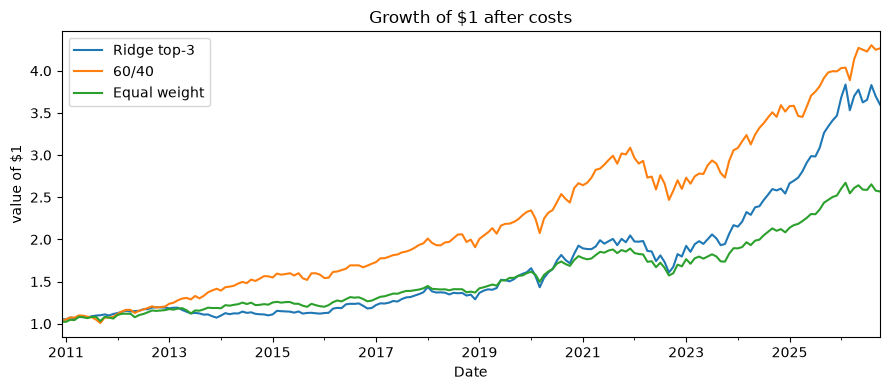

In [ ]:
table = pd.DataFrame({n: metrics(net[n], turn[n]) for n in net})  # Comparative portfolio performance metrics table
display(table.round(3))

pd.DataFrame(net).add(1).cumprod().plot(figsize=(9, 4), title="Growth of $1 after costs")
plt.ylabel("value of $1"); plt.tight_layout(); plt.show()

## 8. Placebo test
If the model had no skill, would random choices do just as well? We build 200 portfolios that each month pick 3 ETFs at random, with the same costs, and see where the strategy's Sharpe falls among them. Random portfolios do not earn zero: they earn roughly the average of the ETFs (minus the costs of trading every month), so this is a fair yardstick, not an easy one.

Random portfolios: average CAGR 4.8%, average Sharpe 0.61
Strategy Sharpe 0.86  ->  p = 0.015


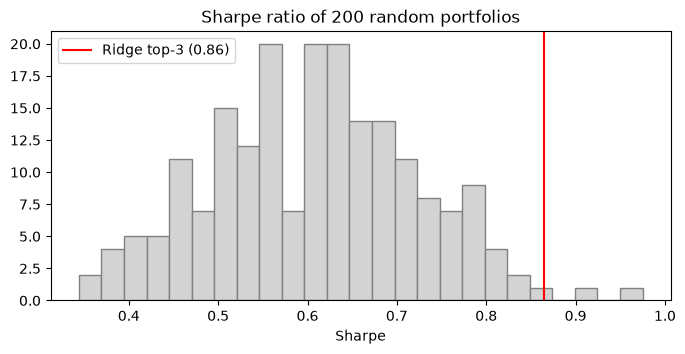

In [ ]:
rng = np.random.default_rng(SEED)  # Random generator instance for reproducibility
placebo_sharpe, placebo_cagr = [], []  # Placebo performance tracking lists
for _ in range(N_PLACEBO):
    w = np.zeros((len(oos), len(TICKERS)))
    for i in range(len(oos)):
        w[i, rng.choice(len(TICKERS), TOP_K, replace=False)] = 1 / TOP_K
    m = metrics(run_portfolio(pd.DataFrame(w, index=oos, columns=TICKERS), COST)[0])
    placebo_sharpe.append(m["Sharpe"]); placebo_cagr.append(m["CAGR"])
placebo_sharpe = np.array(placebo_sharpe)  # Placebo portfolio Sharpe ratios array

strat_sharpe = table.loc["Sharpe", "Ridge top-3"]  # Active strategy Sharpe ratio value
p_value = (1 + (placebo_sharpe >= strat_sharpe).sum()) / (N_PLACEBO + 1)  # Empirical probability of superior performance
print("Random portfolios: average CAGR %.1f%%, average Sharpe %.2f" % (100 * np.mean(placebo_cagr), placebo_sharpe.mean()))
print("Strategy Sharpe %.2f  ->  p = %.3f" % (strat_sharpe, p_value))

plt.figure(figsize=(8, 3.5))
plt.hist(placebo_sharpe, bins=25, color="lightgray", edgecolor="gray")
plt.axvline(strat_sharpe, color="red", label=f"Ridge top-3 ({strat_sharpe:.2f})")
plt.title("Sharpe ratio of 200 random portfolios"); plt.xlabel("Sharpe"); plt.legend(); plt.show()

## 9. Two checks on the code
(a) **Future poisoning**: we replace every price after a chosen date with random numbers and rerun everything. If the weights before that date change, the code is peeking at the future. (b) **Sanity test**: the metric functions must give the answers we can compute by hand (Sharpe about 1.73 and maximum drawdown of -20%).

In [ ]:
# (a) future poisoning
CUT = "2018-12-31"  # Selected date for data poisoning
poisoned = prices.copy()  # Cloned price series for validation
after = poisoned.index > CUT  # Post-cutoff logical date index filter
poisoned.loc[after] = np.random.default_rng(0).uniform(50, 150, size=(after.sum(), len(TICKERS)))
w_poisoned = walk_forward(make_panel(poisoned))  # Simulated weights under poisoned prices
assert w_poisoned.loc[:CUT].equals(w_strat.loc[:CUT]), "weights before the cut changed: look-ahead bug"
changed = (w_poisoned.loc[CUT:].iloc[1:] != w_strat.loc[CUT:].iloc[1:]).any(axis=1).mean()  # Fraction of modified validation weights
print(f"(a) Weights up to {CUT} unchanged ({len(w_strat.loc[:CUT])} months); after it {changed:.0%} changed, so the test can fail.")

# (b) sanity test of the metrics
s_test = metrics(pd.Series([0.02, -0.01, 0.03, -0.02, 0.02, 0.02]))["Sharpe"]  # Hand-computed scenario validation Sharpe metric
dd_test = max_drawdown([100, 110, 120, 96, 108, 125])  # Hand-computed scenario validation drawdown metric
assert abs(s_test - np.sqrt(3)) < 1e-9 and abs(dd_test + 0.20) < 1e-9
print(f"(b) Sharpe test {s_test:.3f} (expected 1.732), max drawdown test {dd_test:.0%} (expected -20%)")

(a) Weights up to 2018-12-31 unchanged (98 months); after it 96% changed, so the test can fail.
(b) Sharpe test 1.732 (expected 1.732), max drawdown test -20% (expected -20%)


## 10. Results and limitations
**What came out** (December 2010 to October 2026, 191 months, after costs):
- **The strategy does not beat 60/40.** It grew 8.4% per year with a Sharpe of 0.86, while the plain 60/40 portfolio grew 9.5% per year with a Sharpe of 1.05 and a slightly smaller worst fall (-20.0% vs -21.5%), trading about 60 times less.
- Against equal weight it is roughly a tie on Sharpe (0.86 vs 0.87): more return, but more risk.
- It does beat random 3-ETF portfolios (p = 0.015). So its choices carry some information, but part of this may simply be that momentum held stocks and gold more often during years when they did well. Beating random picks is not the same as being worth using.
- Both code checks pass: no look-ahead was found, and the metrics give the hand-computed answers.

**Limitations.** About 15 years of out-of-sample data and only 6 ETFs, so few independent decisions. Costs are simplified (a flat 10 bp, no bid-ask changes, no drift between rebalances), there are no taxes, and the risk-free rate is set to zero. The whole design was chosen by me: one test with one p-value does not account for other designs a researcher might have tried.

**Next steps.** Try a random forest with the same validation, compute the Deflated Sharpe Ratio to correct for multiple testing, and monitor feature drift over time.